# Project 2 — Recurrent Encoders for PAWS-Wiki

## 4. GRU and LSTM experiments

This section evaluates recurrent sentence encoders for paraphrase detection. The experiments examine architecture, pretrained embeddings, embedding dimensionality, regularisation, optimisation, and training-set size. Models are compared using Accuracy, Macro-F1, and per-class recall.

All experiments use the same word-level tokenizer and vocabulary as Section 1. Hyperparameters are selected on development data; cross-validation and the official test set are reserved for the final evaluation.

### 4.1 Setup and dataset

The two sentences are encoded by a shared GRU or LSTM. Their final representations are combined using absolute difference and element-wise multiplication, followed by a small classifier.

In [5]:
from pathlib import Path
from dataclasses import dataclass, replace, asdict
from collections import Counter
import hashlib
import json
import random
import time
import urllib.request
import zipfile
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, Subset
from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import accuracy_score, f1_score, recall_score

sys.path.insert(0, str(Path.cwd().parent))
from src.dataset import load_paws
from src.part2_utils import BasicTokenizer, build_vocab

SEED = 42
MAX_LENGTH = 192
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
ROOT = Path("results")
ASSET_DIR = ROOT / "embeddings"
RUN_DIR = ROOT / "recurrent"
DOWNLOAD_DIR = Path("embed_pretrain_data")
for directory in (ASSET_DIR, RUN_DIR, DOWNLOAD_DIR):
    directory.mkdir(parents=True, exist_ok=True)

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

set_seed(SEED)
print("Device:", DEVICE)

Device: cpu


In [6]:
dataset = load_paws()
tokenizer = BasicTokenizer(
    lowercase=True,
    remove_punct=False,
    remove_stopwords=False
)
try:
    tokenizer.tokens("A short example.")
except LookupError:
    import nltk
    nltk.download("punkt", quiet=True)
    nltk.download("punkt_tab", quiet=True)

train_texts = list(dataset["train"]["sentence1"]) + list(dataset["train"]["sentence2"])
vocab, counts = build_vocab(train_texts, tokenizer)
tokenizer.vocab = vocab

assert vocab.index("<pad>") == 0 and vocab.index("<unk>") == 1
print(f"Training pairs: {len(dataset['train']):,}")
print(f"Vocabulary: {len(vocab):,} tokens")

Removed 63 examples from 31 conflicting pairs.
Training examples remaining: 49,338
Training pairs: 49,338
Vocabulary: 31,479 tokens


### 4.2 Pretrained embeddings

GloVe 6B (100d and 300d) and fastText (300d) are aligned to the same training vocabulary. The original archives are downloaded only once from their official sources. GloVe has no header; the fastText vector file has a header.

Previously generated matrices are reused only when a matching vocabulary and preparation manifest are available.

In [7]:
SOURCES = {
    "glove100": {
        "url": "https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip",
        "archive": "glove.6B.zip",
        "member": "glove.6B.100d.txt",
        "dim": 100
    },
    "glove300": {
        "url": "https://downloads.cs.stanford.edu/nlp/data/glove.6B.zip",
        "archive": "glove.6B.zip",
        "member": "glove.6B.300d.txt",
        "dim": 300
    },
    "fasttext300": {
        "url": "https://dl.fbaipublicfiles.com/fasttext/vectors-english/wiki-news-300d-1M.vec.zip",
        "archive": "wiki-news-300d-1M.vec.zip",
        "member": "wiki-news-300d-1M.vec",
        "dim": 300
    }
}

def download_archive(source):
    target = DOWNLOAD_DIR / source["archive"]
    if target.exists() and zipfile.is_zipfile(target):
        return target
    temporary = target.with_suffix(target.suffix + ".part")
    print(f"Downloading {target.name}")
    try:
        with urllib.request.urlopen(source["url"], timeout=120) as response, temporary.open("wb") as file:
            while chunk := response.read(1024 * 1024):
                file.write(chunk)
        if not zipfile.is_zipfile(temporary):
            raise ValueError(f"Invalid archive: {target.name}")
        temporary.replace(target)
    finally:
        temporary.unlink(missing_ok=True)
    return target

def create_embedding_matrix(archive, source, words, seed=SEED):
    dim = source["dim"]
    lookup = {word: idx for idx, word in enumerate(words)}
    matrix = np.random.default_rng(seed).normal(0, 0.1, (len(words), dim)).astype(np.float32)
    matrix[0] = 0
    found = np.zeros(len(words), dtype=bool)

    with zipfile.ZipFile(archive) as z:
        with z.open(source["member"]) as file:
            for line_no, line in enumerate(file):
                parts = line.split()
                if line_no == 0 and len(parts) == 2 and parts[1] == str(dim).encode():
                    continue
                if line_no == 0 and len(parts) != dim + 1:
                    raise ValueError(f"Unexpected embedding format in {source['member']}")
                if len(parts) != dim + 1:
                    continue

                word = parts[0].decode("utf-8", errors="replace").lower()
                idx = lookup.get(word)
                if idx is None or idx < 2 or found[idx]:
                    continue

                vector = np.fromstring(b" ".join(parts[1:]).decode("ascii"), sep=" ", dtype=np.float32)
                if len(vector) == dim and np.isfinite(vector).all():
                    matrix[idx] = vector
                    found[idx] = True

    if not found[2:].any():
        raise ValueError("No vocabulary words matched the pretrained vectors.")
    matrix[1] = matrix[found].mean(axis=0)
    return torch.from_numpy(matrix), found

def prepare_embeddings(vocab, counts):
    words = [vocab.word(i) for i in range(len(vocab))]
    fingerprint = hashlib.sha256(json.dumps(words, ensure_ascii=False).encode()).hexdigest()
    manifest_file = ASSET_DIR / "manifest.json"

    if manifest_file.exists():
        old = json.loads(manifest_file.read_text(encoding="utf-8"))
        if (old.get("version") == 1 and old.get("vocab_sha256") == fingerprint
                and all((ASSET_DIR / f"E_{name}.pt").exists() for name in SOURCES)):
            print("Using previously prepared embeddings.")
            return pd.DataFrame(old["coverage"])

    coverage = []
    for name, source in SOURCES.items():
        archive = download_archive(source)
        matrix, found = create_embedding_matrix(archive, source, words)
        torch.save(matrix, ASSET_DIR / f"E_{name}.pt")
        oov_words = [w for i, w in enumerate(words) if i >= 2 and not found[i]]
        token_total = sum(counts[w] for w in words[2:])
        coverage.append({
            "embedding": name,
            "dimension": source["dim"],
            "OOV_types": len(oov_words) / max(len(words)-2, 1),
            "OOV_tokens": sum(counts[w] for w in oov_words) / max(token_total, 1)
        })

    manifest_file.write_text(json.dumps({
        "version": 1, "vocab_sha256": fingerprint,
        "coverage": coverage
    }, indent=2), encoding="utf-8")
    return pd.DataFrame(coverage)

coverage = prepare_embeddings(vocab, counts)
display(coverage.style.format({"OOV_types": "{:.2%}", "OOV_tokens": "{:.2%}"}))

MATRICES = {
    name: torch.load(ASSET_DIR / f"E_{name}.pt", map_location="cpu", weights_only=True)
    for name in SOURCES
}
for name, matrix in MATRICES.items():
    assert matrix.shape == (len(vocab), SOURCES[name]["dim"])

,embedding,dimension,OOV_types,OOV_tokens
0,glove100,100,13.66%,1.81%
1,glove300,300,13.66%,1.81%
2,fasttext300,300,9.55%,2.36%


### 4.3 Sequence preparation

Sentence order is preserved. Padding is excluded from the recurrent updates using packed sequences. The same encoder weights are used for both sentences in each PAWS pair.

In [8]:
class PAWSPairs(Dataset):
    def __init__(self, split, tokenizer, max_length=MAX_LENGTH):
        self.labels = np.asarray(split["label"], dtype=int)
        self.sentences1 = list(split["sentence1"])
        self.sentences2 = list(split["sentence2"])
        self.groups = np.asarray([
            "\0".join(sorted((a, b))) for a, b in zip(self.sentences1, self.sentences2)
        ])
        self.truncated = 0

        def encode(text):
            ids = tokenizer.ids(text)
            self.truncated += len(ids) > max_length
            return torch.tensor(ids[:max_length] or [tokenizer.vocab.default_index], dtype=torch.long)

        self.a = [encode(s) for s in self.sentences1]
        self.b = [encode(s) for s in self.sentences2]

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        return self.a[idx], self.b[idx], int(self.labels[idx]), idx

def collate_pairs(batch):
    x1 = pad_sequence([item[0] for item in batch], batch_first=True, padding_value=0)
    x2 = pad_sequence([item[1] for item in batch], batch_first=True, padding_value=0)
    labels = torch.tensor([item[2] for item in batch], dtype=torch.long)
    row_ids = torch.tensor([item[3] for item in batch], dtype=torch.long)
    return x1, x2, labels, row_ids

def make_loader(data, indices, batch_size, shuffle=False):
    return DataLoader(
        Subset(data, [int(i) for i in indices]),
        batch_size=batch_size, shuffle=shuffle,
        collate_fn=collate_pairs, num_workers=0
    )

train_data = PAWSPairs(dataset["train"], tokenizer)
print(f"Truncated sentences: {train_data.truncated:,} / {2 * len(train_data):,}")

Truncated sentences: 0 / 98,676


### 4.4 Model

The recurrent hidden state represents a sentence. Bidirectional models concatenate the final states from both directions. The classifier receives \([|h_1-h_2|,\,h_1 \odot h_2]\), making the prediction invariant to swapping the sentence order.

In [9]:
@dataclass(frozen=True)
class Config:
    name: str = "LSTM_base"
    encoder: str = "lstm"
    embedding: str = "glove300"
    hidden_size: int = 128
    layers: int = 1
    bidirectional: bool = False
    freeze_embeddings: bool = True
    random_embeddings: bool = False
    word_dropout: float = 0.0
    classifier_dropout: float = 0.1
    rnn_dropout: float = 0.0
    lr: float = 1e-3
    weight_decay: float = 1e-4
    batch_size: int = 64
    epochs: int = 20
    patience: int = 3

class PairClassifier(nn.Module):
    def __init__(self, matrix, cfg):
        super().__init__()
        if cfg.random_embeddings and cfg.freeze_embeddings:
            raise ValueError("Random embeddings must be trainable.")

        weights = matrix.clone().float()
        if cfg.random_embeddings:
            weights.normal_(0, 0.1)
        weights[0].zero_()
        self.embedding = nn.Embedding.from_pretrained(
            weights, freeze=cfg.freeze_embeddings, padding_idx=0
        )
        self.word_dropout = cfg.word_dropout
        self.encoder_type = cfg.encoder
        self.bidirectional = cfg.bidirectional

        recurrent = nn.GRU if cfg.encoder == "gru" else nn.LSTM
        self.rnn = recurrent(
            input_size=weights.shape[1],
            hidden_size=cfg.hidden_size,
            num_layers=cfg.layers,
            bidirectional=cfg.bidirectional,
            batch_first=True,
            dropout=cfg.rnn_dropout if cfg.layers > 1 else 0
        )
        sentence_dim = cfg.hidden_size * (2 if cfg.bidirectional else 1)
        self.classifier = nn.Sequential(
            nn.Dropout(cfg.classifier_dropout),
            nn.Linear(2 * sentence_dim, 128),
            nn.ReLU(),
            nn.Dropout(cfg.classifier_dropout),
            nn.Linear(128, 2)
        )

    def encode(self, ids):
        valid = ids.ne(0)
        embeddings = self.embedding(ids)
        if self.training and self.word_dropout > 0:
            drop = (torch.rand_like(ids, dtype=torch.float32) < self.word_dropout) & valid
            embeddings = embeddings.masked_fill(drop.unsqueeze(-1), 0)

        lengths = valid.sum(dim=1).clamp_min(1).cpu()
        packed = pack_padded_sequence(embeddings, lengths, batch_first=True, enforce_sorted=False)
        _, state = self.rnn(packed)
        hidden = state[0] if self.encoder_type == "lstm" else state

        if self.bidirectional:
            return torch.cat([hidden[-2], hidden[-1]], dim=1)
        return hidden[-1]

    def forward(self, sentence1, sentence2):
        h1 = self.encode(sentence1)
        h2 = self.encode(sentence2)
        pair = torch.cat([torch.abs(h1 - h2), h1 * h2], dim=1)
        return self.classifier(pair)

BASE = Config()

### 4.5 Evaluation protocol

The training set is divided into three group-disjoint subsets: training, inner validation for early stopping, and a development set for comparing configurations. Exact or reversed sentence pairs remain in the same group. The official test set is not used during model selection.

In [10]:
def grouped_split(data, indices, n_splits=10, seed=SEED):
    indices = np.asarray(indices)
    splitter = StratifiedGroupKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    y = data.labels[indices]
    g = data.groups[indices]
    a, b = next(splitter.split(np.zeros(len(indices)), y, g))
    return indices[a], indices[b]

all_train = np.arange(len(train_data))
development_train, selection_idx = grouped_split(train_data, all_train, seed=SEED)
fit_idx, early_idx = grouped_split(train_data, development_train, seed=SEED+1)

assert not (set(train_data.groups[fit_idx]) & set(train_data.groups[early_idx]))
assert not (set(train_data.groups[development_train]) & set(train_data.groups[selection_idx]))

print(f"Fit: {len(fit_idx):,} | Early stopping: {len(early_idx):,} | Model selection: {len(selection_idx):,}")

Fit: 39,963 | Early stopping: 4,441 | Model selection: 4,934


In [11]:
def evaluate(model, loader, device=DEVICE):
    model.eval()
    true, predictions, probabilities, row_ids = [], [], [], []
    total_loss, total = 0.0, 0
    loss_fn = nn.CrossEntropyLoss(reduction="sum")

    with torch.inference_mode():
        for x1, x2, y, indices in loader:
            logits = model(x1.to(device), x2.to(device))
            total_loss += loss_fn(logits, y.to(device)).item()
            scores = logits.softmax(dim=1)[:, 1].cpu().numpy()

            true.extend(y.tolist())
            predictions.extend((scores >= 0.5).astype(int).tolist())
            probabilities.extend(scores.tolist())
            row_ids.extend(indices.tolist())
            total += len(y)

    result = {
        "loss": total_loss / total,
        "accuracy": accuracy_score(true, predictions),
        "macro_f1": f1_score(true, predictions, average="macro", zero_division=0),
        "recall_0": recall_score(true, predictions, pos_label=0, zero_division=0),
        "recall_1": recall_score(true, predictions, pos_label=1, zero_division=0)
    }
    preds = pd.DataFrame({
        "row_id": row_ids, "true": true,
        "predicted": predictions, "probability_1": probabilities
    })
    return result, preds

def train_and_evaluate(cfg, training_indices, early_indices, evaluation_data,
                       evaluation_indices, folder, seed=SEED, save_weights=False):
    set_seed(seed)
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)

    model = PairClassifier(MATRICES[cfg.embedding], cfg).to(DEVICE)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=cfg.lr, weight_decay=cfg.weight_decay)
    criterion = nn.CrossEntropyLoss()

    train_loader = make_loader(train_data, training_indices, cfg.batch_size, shuffle=True)
    early_loader = make_loader(train_data, early_indices, cfg.batch_size)
    eval_loader = make_loader(evaluation_data, evaluation_indices, cfg.batch_size)

    best_loss, best_epoch, best_state = float("inf"), 0, None
    history = []
    start = time.perf_counter()

    for epoch in range(1, cfg.epochs + 1):
        model.train()
        training_loss, n_train = 0.0, 0

        for x1, x2, y, _ in train_loader:
            optimizer.zero_grad(set_to_none=True)
            logits = model(x1.to(DEVICE), x2.to(DEVICE))
            loss = criterion(logits, y.to(DEVICE))
            loss.backward()
            nn.utils.clip_grad_norm_(params, max_norm=1.0)
            optimizer.step()
            training_loss += loss.item() * len(y)
            n_train += len(y)

        inner, _ = evaluate(model, early_loader)
        history.append({
            "epoch": epoch,
            "train_loss": training_loss / n_train,
            "val_loss": inner["loss"],
            "val_macro_f1": inner["macro_f1"]
        })
        if inner["loss"] < best_loss - 1e-6:
            best_loss, best_epoch = inner["loss"], epoch
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
        elif epoch - best_epoch >= cfg.patience:
            break

    model.load_state_dict(best_state)
    scores, preds = evaluate(model, eval_loader)
    row = {
        **asdict(cfg), **{f"eval_{k}": float(v) for k, v in scores.items()},
        "best_epoch": best_epoch, "n_train": len(training_indices),
        "trainable_parameters": sum(p.numel() for p in model.parameters() if p.requires_grad),
        "seconds": round(time.perf_counter() - start, 1),
        "seed": seed
    }

    pd.DataFrame(history).to_csv(folder / "history.csv", index=False)
    preds.to_csv(folder / "predictions.csv", index=False)
    (folder / "metrics.json").write_text(json.dumps(row, indent=2), encoding="utf-8")
    if save_weights:
        torch.save(best_state, folder / "model.pt")

    del model, optimizer
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    return row

def study(name, configurations, indices=fit_idx, seed=SEED):
    rows = []
    for cfg in configurations:
        path = RUN_DIR / name / cfg.name
        row = train_and_evaluate(
            cfg, indices, early_idx, train_data,
            selection_idx, path, seed=seed
        )
        rows.append({"study": name, **row})
        print(f"{cfg.name}: Macro-F1={row['eval_macro_f1']:.3f} | Accuracy={row['eval_accuracy']:.3f}")

    frame = pd.DataFrame(rows)
    frame.to_csv(RUN_DIR / f"{name}.csv", index=False)
    return frame

def show_results(frame):
    display(frame[[
        "name", "encoder", "embedding", "eval_accuracy",
        "eval_macro_f1", "eval_recall_1", "trainable_parameters"
    ]].sort_values("eval_macro_f1", ascending=False).reset_index(drop=True))

### 4.6 Recurrent architecture

GRU and LSTM are compared under the same training conditions. Directionality and number of recurrent layers are varied separately. Bidirectional encoders have larger sentence representations and more parameters.

In [12]:
architecture_configs = [
    replace(BASE, name="GRU_1layer", encoder="gru"),
    replace(BASE, name="LSTM_1layer", encoder="lstm"),
    replace(BASE, name="GRU_bidirectional", encoder="gru", bidirectional=True),
    replace(BASE, name="LSTM_bidirectional", encoder="lstm", bidirectional=True),
    replace(BASE, name="GRU_2layers", encoder="gru", layers=2),
    replace(BASE, name="LSTM_2layers", encoder="lstm", layers=2)
]
architecture_results = study("architecture", architecture_configs)
show_results(architecture_results)

best_arch_name = architecture_results.sort_values("eval_macro_f1", ascending=False).iloc[0]["name"]
reference = replace(next(c for c in architecture_configs if c.name == best_arch_name), name="reference")
print("Reference architecture:", reference.encoder, "| bidirectional:", reference.bidirectional,
      "| layers:", reference.layers)

GRU_1layer: Macro-F1=0.847 | Accuracy=0.850
LSTM_1layer: Macro-F1=0.830 | Accuracy=0.834
GRU_bidirectional: Macro-F1=0.856 | Accuracy=0.858
LSTM_bidirectional: Macro-F1=0.832 | Accuracy=0.833
GRU_2layers: Macro-F1=0.833 | Accuracy=0.835
LSTM_2layers: Macro-F1=0.834 | Accuracy=0.837


,name,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_1,trainable_parameters
0,GRU_bidirectional,gru,glove300,0.858330,0.856065,0.829358,396162
1,GRU_1layer,gru,glove300,0.849615,0.846562,0.801835,198274
2,LSTM_2layers,lstm,glove300,0.837252,0.834072,0.790826,385410
3,GRU_2layers,gru,glove300,0.834820,0.832869,0.822477,297346
4,LSTM_bidirectional,lstm,glove300,0.833401,0.831616,0.826606,506242
5,LSTM_1layer,lstm,glove300,0.833604,0.830275,0.784862,253314


Reference architecture: gru | bidirectional: True | layers: 1


### 4.7 Hidden-state size

The hidden size controls the recurrent state dimension, independently of the embedding dimension.

In [13]:
hidden_configs = [
    replace(reference, name=f"hidden_{hidden}", hidden_size=hidden)
    for hidden in (64, 128, 256)
]
hidden_results = study("hidden_size", hidden_configs)
show_results(hidden_results)

hidden_64: Macro-F1=0.854 | Accuracy=0.857
hidden_128: Macro-F1=0.856 | Accuracy=0.858
hidden_256: Macro-F1=0.848 | Accuracy=0.851


,name,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_1,trainable_parameters
0,hidden_128,gru,glove300,0.858330,0.856065,0.829358,396162
1,hidden_64,gru,glove300,0.856506,0.853660,0.811468,173698
2,hidden_256,gru,glove300,0.851236,0.848476,0.810550,988546


### 4.8 Pretraining and fine-tuning embeddings

This experiment compares GloVe and fastText at 300 dimensions, and pretrained frozen, pretrained trainable, and randomly initialised trainable embeddings.

In [14]:
embedding_configs = [
    replace(reference, name="GloVe_frozen", embedding="glove300",
            freeze_embeddings=True, random_embeddings=False),
    replace(reference, name="fastText_frozen", embedding="fasttext300",
            freeze_embeddings=True, random_embeddings=False),
    replace(reference, name="GloVe_trainable", embedding="glove300",
            freeze_embeddings=False, random_embeddings=False),
    replace(reference, name="GloVe_random", embedding="glove300",
            freeze_embeddings=False, random_embeddings=True)
]
embedding_results = study("embeddings", embedding_configs)
show_results(embedding_results)

GloVe_frozen: Macro-F1=0.856 | Accuracy=0.858
fastText_frozen: Macro-F1=0.850 | Accuracy=0.852
GloVe_trainable: Macro-F1=0.873 | Accuracy=0.874
GloVe_random: Macro-F1=0.861 | Accuracy=0.863


,name,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_1,trainable_parameters
0,GloVe_trainable,gru,glove300,0.874341,0.872973,0.872018,9839862
1,GloVe_random,gru,glove300,0.862586,0.860895,0.851376,9839862
2,GloVe_frozen,gru,glove300,0.858330,0.856065,0.829358,396162
3,fastText_frozen,gru,fasttext300,0.852250,0.850301,0.835321,396162


### 4.9 Embedding dimension

GloVe 100d and 300d are compared using the same recurrent architecture and hidden size. This isolates embedding dimensionality from the choice of embedding family.

In [15]:
dimension_configs = [
    replace(reference, name="GloVe_100d", embedding="glove100"),
    replace(reference, name="GloVe_300d", embedding="glove300")
]
dimension_results = study("dimensions", dimension_configs)
show_results(dimension_results)

GloVe_100d: Macro-F1=0.849 | Accuracy=0.852
GloVe_300d: Macro-F1=0.856 | Accuracy=0.858


,name,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_1,trainable_parameters
0,GloVe_300d,gru,glove300,0.85833,0.856065,0.829358,396162
1,GloVe_100d,gru,glove100,0.85225,0.848971,0.797706,242562


### 4.10 Regularisation and overfitting

Word dropout, classifier dropout, and weight decay are tested independently. Training and validation losses are inspected for overfitting.

In [16]:
regularisation_configs = [
    replace(reference, name="regularisation_base"),
    replace(reference, name="word_dropout_0.1", word_dropout=0.1),
    replace(reference, name="word_dropout_0.2", word_dropout=0.2),
    replace(reference, name="classifier_dropout_0.3", classifier_dropout=0.3),
    replace(reference, name="weight_decay_0.001", weight_decay=1e-3)
]
regularisation_results = study("regularisation", regularisation_configs)
show_results(regularisation_results)

regularisation_base: Macro-F1=0.856 | Accuracy=0.858
word_dropout_0.1: Macro-F1=0.849 | Accuracy=0.851
word_dropout_0.2: Macro-F1=0.818 | Accuracy=0.818
classifier_dropout_0.3: Macro-F1=0.860 | Accuracy=0.862
weight_decay_0.001: Macro-F1=0.856 | Accuracy=0.858


,name,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_1,trainable_parameters
0,classifier_dropout_0.3,gru,glove300,0.862181,0.859685,0.824771,396162
1,regularisation_base,gru,glove300,0.858330,0.856065,0.829358,396162
2,weight_decay_0.001,gru,glove300,0.858127,0.856041,0.834862,396162
3,word_dropout_0.1,gru,glove300,0.850831,0.849258,0.847248,396162
4,word_dropout_0.2,gru,glove300,0.818403,0.817943,0.869266,396162


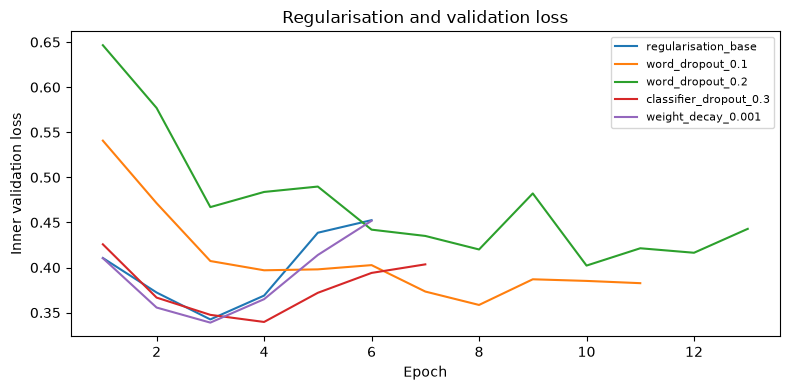

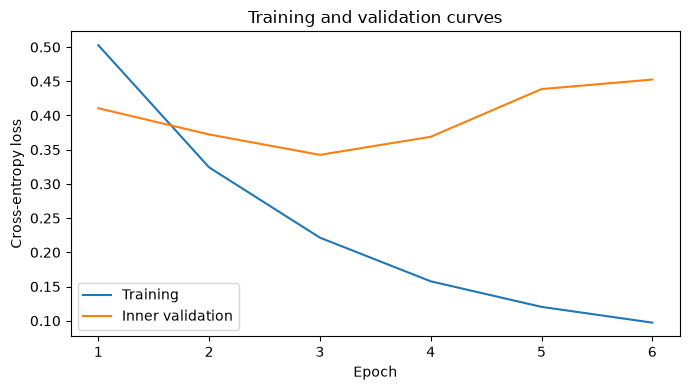

In [17]:
plt.figure(figsize=(8, 4))
for cfg in regularisation_configs:
    history = pd.read_csv(RUN_DIR / "regularisation" / cfg.name / "history.csv")
    plt.plot(history["epoch"], history["val_loss"], label=cfg.name)
plt.xlabel("Epoch")
plt.ylabel("Inner validation loss")
plt.title("Regularisation and validation loss")
plt.legend(fontsize=8)
plt.tight_layout()
plt.show()

baseline_history = pd.read_csv(
    RUN_DIR / "regularisation" / "regularisation_base" / "history.csv"
)
plt.figure(figsize=(7, 4))
plt.plot(baseline_history["epoch"], baseline_history["train_loss"], label="Training")
plt.plot(baseline_history["epoch"], baseline_history["val_loss"], label="Inner validation")
plt.xlabel("Epoch")
plt.ylabel("Cross-entropy loss")
plt.title("Training and validation curves")
plt.legend()
plt.tight_layout()
plt.show()

### 4.11 Optimisation

Learning rate and batch size are tested while keeping the model architecture unchanged.

In [18]:
optimisation_configs = [
    replace(reference, name="lr_0.001", lr=1e-3),
    replace(reference, name="lr_0.0003", lr=3e-4),
    replace(reference, name="lr_0.0001", lr=1e-4),
    replace(reference, name="batch_128", batch_size=128)
]
optimisation_results = study("optimisation", optimisation_configs)
show_results(optimisation_results)

lr_0.001: Macro-F1=0.856 | Accuracy=0.858
lr_0.0003: Macro-F1=0.834 | Accuracy=0.836
lr_0.0001: Macro-F1=0.822 | Accuracy=0.825
batch_128: Macro-F1=0.838 | Accuracy=0.840


,name,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_1,trainable_parameters
0,lr_0.001,gru,glove300,0.858330,0.856065,0.829358,396162
1,batch_128,gru,glove300,0.839684,0.837718,0.825688,396162
2,lr_0.0003,gru,glove300,0.836036,0.833730,0.812844,396162
3,lr_0.0001,gru,glove300,0.824686,0.822081,0.796330,396162


### 4.12 Training-set size

The effect of training data is measured using nested, class-stratified subsets. Pretrained frozen, pretrained trainable, and random trainable embeddings are compared. Every model is evaluated on the same independent development set.

In [19]:
def data_subsets(indices, labels, fractions=(0.1, 0.25, 0.5, 1.0), seed=SEED):
    rng = np.random.default_rng(seed)
    indices = np.asarray(indices)
    by_class = {}
    for label in np.unique(labels[indices]):
        rows = indices[labels[indices] == label].copy()
        rng.shuffle(rows)
        by_class[label] = rows

    return {
        fraction: np.sort(np.concatenate([
            rows[:max(1, round(fraction * len(rows)))] for rows in by_class.values()
        ]))
        for fraction in fractions
    }

subsets = data_subsets(fit_idx, train_data.labels)
size_rows = []
for fraction, indices in subsets.items():
    for kind in ("pretrained_frozen", "pretrained_trainable", "random_trainable"):
        cfg = replace(
            reference, name=f"size_{fraction:g}_{kind}",
            embedding="glove300",
            freeze_embeddings=(kind == "pretrained_frozen"),
            random_embeddings=(kind == "random_trainable")
        )
        row = train_and_evaluate(
            cfg, indices, early_idx, train_data, selection_idx,
            RUN_DIR / "data_size" / cfg.name
        )
        size_rows.append({"study": "data_size", "fraction": fraction, **row})
        print(f"{fraction:.0%} | {kind}: Macro-F1={row['eval_macro_f1']:.3f}")

size_results = pd.DataFrame(size_rows)
size_results.to_csv(RUN_DIR / "data_size.csv", index=False)
display(size_results[["name", "n_train", "eval_accuracy", "eval_macro_f1"]])

10% | pretrained_frozen: Macro-F1=0.702
10% | pretrained_trainable: Macro-F1=0.706
10% | random_trainable: Macro-F1=0.696
25% | pretrained_frozen: Macro-F1=0.755
25% | pretrained_trainable: Macro-F1=0.764
25% | random_trainable: Macro-F1=0.702
50% | pretrained_frozen: Macro-F1=0.808
50% | pretrained_trainable: Macro-F1=0.815
50% | random_trainable: Macro-F1=0.797
100% | pretrained_frozen: Macro-F1=0.856
100% | pretrained_trainable: Macro-F1=0.873
100% | random_trainable: Macro-F1=0.861


,name,n_train,eval_accuracy,eval_macro_f1
0,size_0.1_pretrained_frozen,3997,0.709972,0.702121
1,size_0.1_pretrained_trainable,3997,0.708350,0.705645
2,size_0.1_random_trainable,3997,0.702675,0.696151
3,size_0.25_pretrained_frozen,9991,0.765505,0.755355
4,size_0.25_pretrained_trainable,9991,0.773206,0.764341
5,size_0.25_random_trainable,9991,0.715444,0.702107
6,size_0.5_pretrained_frozen,19982,0.813944,0.808058
7,size_0.5_pretrained_trainable,19982,0.821848,0.815153
8,size_0.5_random_trainable,19982,0.801784,0.797121
9,size_1_pretrained_frozen,39963,0.858330,0.856065


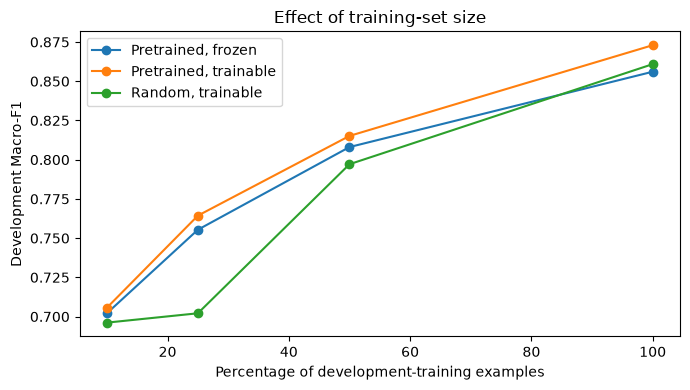

In [20]:
plt.figure(figsize=(7, 4))
conditions = {
    "pretrained_frozen": "Pretrained, frozen",
    "pretrained_trainable": "Pretrained, trainable",
    "random_trainable": "Random, trainable"
}
for kind, label in conditions.items():
    part = size_results[size_results["name"].str.endswith(kind)].sort_values("fraction")
    plt.plot(part["fraction"] * 100, part["eval_macro_f1"], "o-", label=label)
plt.xlabel("Percentage of development-training examples")
plt.ylabel("Development Macro-F1")
plt.title("Effect of training-set size")
plt.legend()
plt.tight_layout()
plt.show()

### 4.13 Model selection

The best complete-data configuration is selected using development Macro-F1. Training-set-size experiments below 100% are excluded from this selection. Selection results are exploratory. The subsequent cross-validation assesses the stability of the selected configuration across different data partitions and random seeds. However, because hyperparameters were selected using a subset of the same training dataset, cross-validation is not fully independent of model selection. The official test set is therefore retained for final evaluation.

In [21]:
screening_results = pd.concat([
    architecture_results,
    hidden_results,
    embedding_results,
    dimension_results,
    regularisation_results,
    optimisation_results,
    size_results[size_results["fraction"] == 1.0]
], ignore_index=True)

config_lookup = {
    cfg.name: cfg for cfg in (
        architecture_configs + hidden_configs + embedding_configs +
        dimension_configs + regularisation_configs + optimisation_configs
    )
}
for fraction in (1.0,):
    for kind in ("pretrained_frozen", "pretrained_trainable", "random_trainable"):
        name = f"size_{fraction:g}_{kind}"
        config_lookup[name] = replace(
            reference, name=name, embedding="glove300",
            freeze_embeddings=(kind == "pretrained_frozen"),
            random_embeddings=(kind == "random_trainable")
        )

ranked = screening_results.sort_values(
    ["eval_macro_f1", "eval_accuracy"], ascending=False
).reset_index(drop=True)
display(ranked[[
    "study", "name", "encoder", "embedding", "eval_accuracy",
    "eval_macro_f1", "eval_recall_1"
]].head(12))

selected = config_lookup[ranked.iloc[0]["name"]]
print("Selected model:", selected.name, "|", selected.encoder, "|", selected.embedding)

,study,name,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_1
0,embeddings,GloVe_trainable,gru,glove300,0.874341,0.872973,0.872018
1,data_size,size_1_pretrained_trainable,gru,glove300,0.874341,0.872973,0.872018
2,embeddings,GloVe_random,gru,glove300,0.862586,0.860895,0.851376
3,data_size,size_1_random_trainable,gru,glove300,0.862586,0.860895,0.851376
4,regularisation,classifier_dropout_0.3,gru,glove300,0.862181,0.859685,0.824771
5,architecture,GRU_bidirectional,gru,glove300,0.858330,0.856065,0.829358
6,hidden_size,hidden_128,gru,glove300,0.858330,0.856065,0.829358
7,embeddings,GloVe_frozen,gru,glove300,0.858330,0.856065,0.829358
8,dimensions,GloVe_300d,gru,glove300,0.858330,0.856065,0.829358
9,regularisation,regularisation_base,gru,glove300,0.858330,0.856065,0.829358


Selected model: GloVe_trainable | gru | glove300


### 4.14 Final cross-validation

The selected configuration and a matched recurrent alternative (GRU or LSTM) are evaluated using stratified, group-aware five-fold cross-validation with three random seeds.

For each seed, the training dataset is partitioned into five folds. Each fold is used once for evaluation, while the remaining data are used for training, with a separate inner validation subset for early stopping. Both architectures use identical partitions and training conditions, allowing paired comparisons.

Accuracy and Macro-F1 are averaged across the five folds for each seed. The final mean and standard deviation are computed across the three seed-level averages.

This procedure assesses performance variability across different data partitions and random initialisations. However, since the hyperparameters were previously selected using a subset of the same training dataset, the cross-validation scores are not fully independent of model selection. They should therefore be interpreted as a robustness analysis rather than an unbiased final generalisation estimate.

The official PAWS test set remains reserved for final evaluation.

In [22]:
cv_models = [
    replace(selected, name="selected_" + selected.encoder.upper()),
    replace(
        selected,
        name="matched_" + ("GRU" if selected.encoder == "lstm" else "LSTM"),
        encoder="gru" if selected.encoder == "lstm" else "lstm"
    )
]

cv_rows = []
for cfg in cv_models:
    for seed in (0, 1, 2):
        cv = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
        for fold, (outer_train, outer_test) in enumerate(
            cv.split(np.zeros(len(train_data)), train_data.labels, train_data.groups)
        ):
            inner_train, inner_validation = grouped_split(
                train_data, outer_train, seed=seed * 10 + fold
            )
            row = train_and_evaluate(
                cfg, inner_train, inner_validation, train_data, outer_test,
                RUN_DIR / "cv" / cfg.name / f"seed{seed}_fold{fold}",
                seed=seed * 10 + fold
            )
            cv_rows.append({"model": cfg.name, "cv_seed": seed, "fold": fold, **row})
            pd.DataFrame(cv_rows).to_csv(RUN_DIR / "cv_results.csv", index=False)
            print(f"{cfg.name} | seed {seed} | fold {fold}: Macro-F1={row['eval_macro_f1']:.3f}")

cv_results = pd.DataFrame(cv_rows)
seed_means = cv_results.groupby(["model", "cv_seed"], as_index=False)[
    ["eval_accuracy", "eval_macro_f1", "eval_recall_1"]
].mean()
cv_summary = seed_means.groupby("model").agg(
    accuracy_mean=("eval_accuracy", "mean"),
    accuracy_sd=("eval_accuracy", "std"),
    macro_f1_mean=("eval_macro_f1", "mean"),
    macro_f1_sd=("eval_macro_f1", "std"),
    recall_1_mean=("eval_recall_1", "mean")
)
display(cv_summary)
cv_summary.to_csv(RUN_DIR / "cv_summary.csv")

selected_GRU | seed 0 | fold 0: Macro-F1=0.861
selected_GRU | seed 0 | fold 1: Macro-F1=0.856
selected_GRU | seed 0 | fold 2: Macro-F1=0.863
selected_GRU | seed 0 | fold 3: Macro-F1=0.863
selected_GRU | seed 0 | fold 4: Macro-F1=0.869
selected_GRU | seed 1 | fold 0: Macro-F1=0.854
selected_GRU | seed 1 | fold 1: Macro-F1=0.865
selected_GRU | seed 1 | fold 2: Macro-F1=0.858
selected_GRU | seed 1 | fold 3: Macro-F1=0.867
selected_GRU | seed 1 | fold 4: Macro-F1=0.866
selected_GRU | seed 2 | fold 0: Macro-F1=0.868
selected_GRU | seed 2 | fold 1: Macro-F1=0.863
selected_GRU | seed 2 | fold 2: Macro-F1=0.868
selected_GRU | seed 2 | fold 3: Macro-F1=0.859
selected_GRU | seed 2 | fold 4: Macro-F1=0.860
matched_LSTM | seed 0 | fold 0: Macro-F1=0.849
matched_LSTM | seed 0 | fold 1: Macro-F1=0.852
matched_LSTM | seed 0 | fold 2: Macro-F1=0.853
matched_LSTM | seed 0 | fold 3: Macro-F1=0.849
matched_LSTM | seed 0 | fold 4: Macro-F1=0.838
matched_LSTM | seed 1 | fold 0: Macro-F1=0.850
matched_LSTM 

,accuracy_mean,accuracy_sd,macro_f1_mean,macro_f1_sd,recall_1_mean
model,,,,,
matched_LSTM,0.854007,0.002600,0.851336,0.003241,0.818612
selected_GRU,0.865438,0.000737,0.862732,0.000806,0.823033


#### Paired GRU–LSTM comparison

Since GRU and LSTM were evaluated on identical cross-validation folds, their differences can be analysed directly for each matched fold.

The following post-hoc analysis uses the saved cross-validation results without retraining. For each metric, the GRU–LSTM difference is calculated within each fold, then averaged across folds for each seed. The final summary reports the mean and standard deviation of these seed-level differences.

This provides a more informative architectural comparison than considering the two models' aggregate scores independently. However, folds and repeated partitions are statistically dependent, so these results are interpreted descriptively rather than as independent observations for a significance test.

In [26]:
# Post-hoc paired comparison: no model training
cv_saved = pd.read_csv(RUN_DIR / "cv_results.csv")

paired_rows = []

for metric in ("eval_accuracy", "eval_macro_f1"):
    wide = cv_saved.pivot(
        index=["cv_seed", "fold"],
        columns="encoder",
        values=metric
    )

    assert {"gru", "lstm"}.issubset(wide.columns)
    assert len(wide) == 15 and wide[["gru", "lstm"]].notna().all().all()

    paired = wide[["gru", "lstm"]].reset_index()
    paired["metric"] = metric
    paired["difference"] = paired["gru"] - paired["lstm"]

    paired_rows.append(paired)

paired_cv = pd.concat(paired_rows, ignore_index=True)

# Average matched folds within each seed
paired_seeds = (
    paired_cv.groupby(["metric", "cv_seed"], as_index=False)
    [["gru", "lstm", "difference"]]
    .mean()
)

# Summary across seed-level averages
paired_summary = (
    paired_seeds.groupby("metric")
    .agg(
        gru_mean=("gru", "mean"),
        lstm_mean=("lstm", "mean"),
        difference_mean=("difference", "mean"),
        difference_sd=("difference", "std")
    )
)

display(paired_seeds.round(4))
display(paired_summary.round(4))

print("Positive difference means GRU performs better.")

paired_cv.to_csv(
    RUN_DIR / "cv_paired_comparison.csv",
    index=False
)

encoder,metric,cv_seed,gru,lstm,difference
0,eval_accuracy,0,0.8656,0.8513,0.0142
1,eval_accuracy,1,0.8646,0.8542,0.0104
2,eval_accuracy,2,0.8661,0.8565,0.0096
3,eval_macro_f1,0,0.8625,0.8481,0.0144
4,eval_macro_f1,1,0.8620,0.8513,0.0108
5,eval_macro_f1,2,0.8636,0.8546,0.0090


,gru_mean,lstm_mean,difference_mean,difference_sd
metric,,,,
eval_accuracy,0.8654,0.8540,0.0114,0.0025
eval_macro_f1,0.8627,0.8513,0.0114,0.0027


Positive difference means GRU performs better.


### 4.15 Official test evaluation

The final selected configuration is evaluated on the official PAWS-Wiki test set, which was not used for training, early stopping, or hyperparameter selection.

The model is trained using the official training dataset, with a separate internal subset reserved for early stopping. The checkpoint with the lowest internal validation loss is restored before test evaluation.

Accuracy, Macro-F1, and per-class recall are reported. Unlike the development and cross-validation scores, the official test results provide a held-out evaluation of the selected configuration.

The distinction between these evaluation stages is important: development results guide hyperparameter selection, cross-validation investigates robustness across partitions and training seeds, and the official test measures performance on an unseen benchmark split.

Differences between cross-validation and test performance may reflect dataset difficulty, sampling characteristics, or remaining selection effects. They should not automatically be attributed to overfitting without further evidence.

The official test results are reported without subsequent hyperparameter tuning.

In [23]:
test_data = PAWSPairs(dataset["test"], tokenizer)
final_fit, final_early = grouped_split(train_data, all_train, seed=SEED + 100)

test_row = train_and_evaluate(
    replace(selected, name="final_test_model"),
    final_fit, final_early,
    test_data, np.arange(len(test_data)),
    RUN_DIR / "official_test",
    seed=SEED, save_weights=True
)
test_table = pd.DataFrame([test_row])[
    ["encoder", "embedding", "eval_accuracy", "eval_macro_f1",
     "eval_recall_0", "eval_recall_1", "best_epoch", "n_train"]
]
display(test_table)

,encoder,embedding,eval_accuracy,eval_macro_f1,eval_recall_0,eval_recall_1,best_epoch,n_train
0,gru,glove300,0.772625,0.772011,0.738799,0.815328,2,44404


### 4.16 Error analysis

The final model's errors are examined according to sentence length, lexical overlap, and out-of-vocabulary token frequency. High-confidence misclassifications are also inspected qualitatively.

An additional word-order diagnostic identifies sentence pairs containing exactly the same multiset of tokens but in a different order. This subset is particularly relevant to PAWS because simple order-invariant pooling cannot distinguish different permutations of the same tokens at the sentence-representation level.

Accuracy on these pairs is compared with accuracy on the remaining test examples. This analysis investigates whether the recurrent encoder handles a particularly challenging type of lexical overlap, although it does not by itself establish that the model has learned syntactic relationships. A direct comparison with embed-and-pool models is required to assess the benefit of order-sensitive encoding.

In [24]:
test_predictions = pd.read_csv(RUN_DIR / "official_test" / "predictions.csv")

def pair_features(a, b):
    tokens_a, tokens_b = tokenizer.tokens(a), tokenizer.tokens(b)
    shared = set(tokens_a) & set(tokens_b)
    union = set(tokens_a) | set(tokens_b)
    return {
        "mean_length": (len(tokens_a) + len(tokens_b)) / 2,
        "jaccard": len(shared) / max(len(union), 1),
        "oov_count": sum(tokenizer.vocab.index(w) == 1 for w in tokens_a + tokens_b)
    }

features = pd.DataFrame([
    pair_features(dataset["test"][int(i)]["sentence1"],
                  dataset["test"][int(i)]["sentence2"])
    for i in test_predictions["row_id"]
])
analysis = pd.concat([test_predictions.reset_index(drop=True), features], axis=1)
analysis["correct"] = analysis["true"] == analysis["predicted"]

for field, bins in [
    ("mean_length", [0, 10, 20, 30, 50, float("inf")]),
    ("jaccard", [0, 0.25, 0.5, 0.75, 0.9, 1.01]),
    ("oov_count", [-1, 0, 1, 2, 5, float("inf")])
]:
    groups = pd.cut(analysis[field], bins=bins, include_lowest=True)
    display(analysis.groupby(groups, observed=True)["correct"].agg(["size", "mean"])
            .rename(columns={"size": "n", "mean": "accuracy"}))

errors = analysis[~analysis["correct"]].copy()
errors["confidence"] = np.where(
    errors["predicted"] == 1,
    errors["probability_1"], 1 - errors["probability_1"]
)
examples = errors.sort_values("confidence", ascending=False).head(10)
examples_table = pd.DataFrame([
    {
        "sentence1": dataset["test"][int(row.row_id)]["sentence1"],
        "sentence2": dataset["test"][int(row.row_id)]["sentence2"],
        "true": row.true, "predicted": row.predicted,
        "confidence": round(row.confidence, 3)
    }
    for row in examples.itertuples()
])
display(examples_table)
analysis.to_csv(RUN_DIR / "test_error_analysis.csv", index=False)

,n,accuracy
mean_length,,
"(-0.001, 10.0]",73,0.602740
"(10.0, 20.0]",3550,0.774930
"(20.0, 30.0]",4196,0.775024
"(30.0, 50.0]",181,0.740331


,n,accuracy
jaccard,,
"(0.5, 0.75]",192,0.750000
"(0.75, 0.9]",4630,0.754428
"(0.9, 1.01]",3178,0.800503


,n,accuracy
oov_count,,
"(-1.001, 0.0]",1468,0.787466
"(0.0, 1.0]",170,0.717647
"(1.0, 2.0]",1923,0.824233
"(2.0, 5.0]",2086,0.743528
"(5.0, inf]",2353,0.750956


,sentence1,sentence2,true,predicted,confidence
0,This is a list of international sporting event...,This is a list of international sporting event...,0,1,1.0
1,The river Redea is a tributary of the Comanca ...,The River Comanca is a tributary of the Redea ...,0,1,1.0
2,The river Dorolea is a tributary of the river ...,The river Cuşma is a tributary of the River Do...,0,1,1.0
3,The River Luhei is a tributary of the Viseu Ri...,The river Vişeu is a tributary of the Luhei Ri...,0,1,1.0
4,The river Cuşma is a tributary of the Dorolea ...,The river Dorolea is a tributary of the Cuşma ...,0,1,1.0
5,The music was composed by Ilaiyaraaja and the ...,The music was composed by Vaali and the lyrics...,0,1,1.0
6,This is a list of the international sporting e...,This is a list of international sporting event...,0,1,1.0
7,The Ducin River is a tributary of the River Du...,The Ducinoiu River is a tributary of the River...,0,1,1.0
8,"Laura Camaur ( January 5 , 1913 - September 13...","Laura Solari ( January 5 , 1913 -- September 1...",0,1,1.0
9,The music was composed by Vaali and lyrics wer...,The music was composed by Ilaiyaraaja and the ...,0,1,1.0


In [25]:
from collections import Counter

def same_words_different_order(a, b):
    ta = tokenizer.tokens(a)
    tb = tokenizer.tokens(b)
    return Counter(ta) == Counter(tb) and ta != tb

analysis["same_bag_reordered"] = [
    same_words_different_order(
        dataset["test"][int(i)]["sentence1"],
        dataset["test"][int(i)]["sentence2"]
    )
    for i in analysis["row_id"]
]

display(
    analysis.groupby("same_bag_reordered")["correct"]
    .agg(n="size", accuracy="mean")
)

,n,accuracy
same_bag_reordered,,
False,7469,0.774267
True,531,0.749529


#### Comparative error analysis across model choices

To investigate which input characteristics explain performance differences between major design choices, predictions from previously trained models are compared on the same development examples.

Two controlled comparisons are considered:

- **BiGRU vs BiLSTM:** isolates the recurrent cell type while keeping the other architectural and training settings fixed.
- **GloVe trainable vs GloVe frozen:** investigates the effect of updating pretrained word embeddings while keeping the recurrent architecture fixed.

Performance is analysed according to sentence length, lexical overlap, and whether the two sentences contain identical multisets of words in different orders. OOV analysis is restricted to the official test set, since the development examples were used to construct the training vocabulary.

For each subgroup, the analysis reports the number of examples, class distribution, Accuracy, and Macro-F1 where both classes are present. Differences in Accuracy are expressed in percentage points.

All comparisons use saved predictions on the same development split, without additional training. Since this split was also used during hyperparameter exploration, the results are interpreted as exploratory error analysis rather than independent generalisation estimates.

In [29]:
model_files = {
    "BiGRU": RUN_DIR / "architecture" / "GRU_bidirectional" / "predictions.csv",
    "BiLSTM": RUN_DIR / "architecture" / "LSTM_bidirectional" / "predictions.csv",
    "GloVe trainable": RUN_DIR / "embeddings" / "GloVe_trainable" / "predictions.csv",
    "GloVe frozen": RUN_DIR / "embeddings" / "GloVe_frozen" / "predictions.csv",
}

comparisons = [
    ("Architecture", "BiGRU", "BiLSTM"),
    ("Embedding update", "GloVe trainable", "GloVe frozen"),
]

# All models must have been evaluated on the same examples.
ids = np.sort(np.asarray(selection_idx, dtype=int))
y = train_data.labels[ids]
preds = {}

for model, path in model_files.items():
    df = pd.read_csv(path)
    assert df["row_id"].is_unique
    df = df.set_index("row_id").sort_index()

    assert np.array_equal(df.index.to_numpy(), ids), model
    assert np.array_equal(df["true"].to_numpy(), y), model

    preds[model] = df["predicted"].to_numpy(dtype=int)

# Compute input characteristics once, shared by all models.
features = pd.DataFrame([
    pair_features(
        train_data.sentences1[i],
        train_data.sentences2[i]
    )
    for i in ids
])

features["reordered"] = [
    same_words_different_order(
        train_data.sentences1[i],
        train_data.sentences2[i]
    )
    for i in ids
]

# Define interpretable subgroups.
reordered = features["reordered"].to_numpy()
high_overlap = features["jaccard"].to_numpy() >= 0.9
long_pair = features["mean_length"].to_numpy() >= 30

subgroups = {
    "All examples": np.ones(len(ids), dtype=bool),
    "Same bag, reordered": reordered,
    "Other pairs": ~reordered,
    "High lexical overlap": high_overlap,
    "Lower lexical overlap": ~high_overlap,
    "Long sentences": long_pair,
    "Shorter sentences": ~long_pair,
}

rows = []

for study, model_a, model_b in comparisons:
    pa, pb = preds[model_a], preds[model_b]

    for subset, mask in subgroups.items():
        if mask.sum() == 0:
            continue

        yt, a, b = y[mask], pa[mask], pb[mask]
        acc_a = accuracy_score(yt, a)
        acc_b = accuracy_score(yt, b)

        # Macro-F1 is only reported when both classes occur.
        both_classes = len(np.unique(yt)) == 2

        rows.append({
            "comparison": study,
            "subset": subset,
            "n": int(mask.sum()),
            "class_1_%": 100 * yt.mean(),
            "model_A": model_a,
            "model_B": model_b,
            "accuracy_A": acc_a,
            "accuracy_B": acc_b,
            "delta_acc_pp": 100 * (acc_a - acc_b),
            "macro_f1_A": (
                f1_score(yt, a, average="macro", zero_division=0)
                if both_classes else np.nan
            ),
            "macro_f1_B": (
                f1_score(yt, b, average="macro", zero_division=0)
                if both_classes else np.nan
            ),
            "A_only_correct": int(((a == yt) & (b != yt)).sum()),
            "B_only_correct": int(((b == yt) & (a != yt)).sum())
        })

comparative_errors = pd.DataFrame(rows)

for study in comparative_errors["comparison"].unique():
    print(f"\n{study}")
    display(
        comparative_errors[
            comparative_errors["comparison"] == study
        ][[
            "subset", "n", "class_1_%",
            "accuracy_A", "accuracy_B", "delta_acc_pp",
            "macro_f1_A", "macro_f1_B",
            "A_only_correct", "B_only_correct"
        ]].round(3)
    )

comparative_errors.to_csv(
    RUN_DIR / "comparative_error_analysis.csv",
    index=False
)

print("Positive delta means model A outperforms model B.")



Architecture


,subset,n,class_1_%,accuracy_A,accuracy_B,delta_acc_pp,macro_f1_A,macro_f1_B,A_only_correct,B_only_correct
0,All examples,4934,44.183,0.858,0.833,2.493,0.856,0.832,355,232
1,"Same bag, reordered",310,23.871,0.926,0.916,0.968,0.902,0.893,14,11
2,Other pairs,4624,45.545,0.854,0.828,2.595,0.852,0.827,341,221
3,High lexical overlap,2030,43.103,0.900,0.873,2.611,0.898,0.872,115,62
4,Lower lexical overlap,2904,44.938,0.830,0.805,2.410,0.826,0.803,240,170
5,Long sentences,222,42.342,0.892,0.806,8.559,0.889,0.804,23,4
6,Shorter sentences,4712,44.270,0.857,0.835,2.207,0.855,0.833,332,228



Embedding update


,subset,n,class_1_%,accuracy_A,accuracy_B,delta_acc_pp,macro_f1_A,macro_f1_B,A_only_correct,B_only_correct
7,All examples,4934,44.183,0.874,0.858,1.601,0.873,0.856,269,190
8,"Same bag, reordered",310,23.871,0.932,0.926,0.645,0.911,0.902,9,7
9,Other pairs,4624,45.545,0.870,0.854,1.665,0.870,0.852,260,183
10,High lexical overlap,2030,43.103,0.911,0.900,1.133,0.910,0.898,77,54
11,Lower lexical overlap,2904,44.938,0.849,0.830,1.928,0.847,0.826,192,136
12,Long sentences,222,42.342,0.856,0.892,-3.604,0.853,0.889,5,13
13,Shorter sentences,4712,44.270,0.875,0.857,1.846,0.874,0.855,264,177


Positive delta means model A outperforms model B.


In [28]:

for study, model_a, model_b in comparisons:
    pa, pb = preds[model_a], preds[model_b]

    examples = []

    for winner, mask in [
        (model_a, (pa == y) & (pb != y)),
        (model_b, (pb == y) & (pa != y))
    ]:
        candidates = np.flatnonzero(mask)

        # Prioritise reordered and high-overlap examples.
        candidates = sorted(
            candidates,
            key=lambda i: (
                not features.iloc[i]["reordered"],
                -features.iloc[i]["jaccard"],
                int(ids[i])
            )
        )

        for i in candidates[:3]:
            examples.append({
                "correct_model": winner,
                "sentence1": train_data.sentences1[ids[i]],
                "sentence2": train_data.sentences2[ids[i]],
                "true": int(y[i]),
                model_a: int(pa[i]),
                model_b: int(pb[i]),
                "reordered": bool(features.iloc[i]["reordered"]),
                "overlap": round(features.iloc[i]["jaccard"], 3)
            })

    print(f"\n{study}: contrasting errors")
    display(pd.DataFrame(examples))



Architecture: contrasting errors


,correct_model,sentence1,sentence2,true,BiGRU,BiLSTM,reordered,overlap
0,BiGRU,Afterwards she taught at secondary schools in ...,Afterwards she taught at secondary schools in ...,0,0,1,True,1.0
1,BiGRU,"More recently , the band has combined extra li...","More recently , the band has combined Extra Li...",0,0,1,True,1.0
2,BiGRU,This was a limited release -- only 300 red vin...,This was a limited release -- only 300 black v...,0,0,1,True,1.0
3,BiLSTM,Cum Posey played for Brown 's Grays from 1932 ...,Cum Posey played from 1932 to 1945 for Brown '...,1,0,1,True,1.0
4,BiLSTM,The term `` non-hereditary spherocytosis '' is...,The term `` non-hereditary spherocytosis '' is...,0,1,0,True,1.0
5,BiLSTM,The station was built in 1915 along the former...,The station was built in 1915 along the former...,0,1,0,True,1.0



Embedding update: contrasting errors


,correct_model,sentence1,sentence2,true,GloVe trainable,GloVe frozen,reordered,overlap
0,GloVe trainable,Cum Posey played for Brown 's Grays from 1932 ...,Cum Posey played from 1932 to 1945 for Brown '...,1,1,0,True,1.0
1,GloVe trainable,The term `` non-hereditary spherocytosis '' is...,The term `` non-hereditary spherocytosis '' is...,0,0,1,True,1.0
2,GloVe trainable,"From 2 June 1969 , lectures were held for the ...","From 2 June 1969 , lectures were held for the ...",0,0,1,True,1.0
3,GloVe frozen,It is bordered to the northeast by the Pacific...,It is bordered to the northeast by the Pacific...,0,1,0,True,1.0
4,GloVe frozen,A section of the route remains in place and is...,A section of the route remains in place and is...,0,1,0,True,1.0
5,GloVe frozen,"Germany ended its support for China in 1938 , ...","In 1938 , Japan ended its support for China un...",0,1,0,True,1.0
